# Proyecto 2 · Asistente multimodal MDK Tuchtlán
**Prototipo académico en Python · Fernanda Gómez Gordillo**

1. Ejecuta las celdas en orden mediante Entorno de ejecución → Ejecutar todas.
2. Cuando se solicite, carga el archivo MDK_imagenes_clasificadas.zip para entrenar y evaluar el clasificador visual.
3. Revisa los resultados del clasificador de intenciones y del clasificador de imágenes, incluidas sus matrices de confusión.
4. En la sección de integración, escribe una consulta y carga una fotografía nueva para observar la respuesta conjunta del sistema.

Alcance: el asistente responde consultas informativas sobre MDK Tuchtlán y reconoce fotografías de cascos, guantes, petos y uniformes. Cuando una consulta o imagen no puede interpretarse con claridad, remite a la escuela.

Limitaciones: los ejemplos de texto fueron redactados para esta práctica y el conjunto visual es pequeño. Los precios, promociones y requisitos deben confirmarse con la escuela antes de utilizar el asistente fuera del ejercicio académico.

In [ ]:
%pip -q install nltk scikit-learn tensorflow matplotlib pillow

## 1. Problema y arquitectura

El chatbot original atiende dudas recurrentes sobre horarios, inscripción, costos, ubicación, uniforme y protección. Se conserva como fuente de respuestas controladas. En este avance agregamos un SVM para estudiar seis intenciones y EfficientNetB0 para reconocer el artículo principal de una foto. En la demostración integrada, las reglas responden información conocida; el modelo textual ayuda cuando las reglas no encuentran intención. Con una imagen, el sistema comunica la categoría visual junto con la respuesta conversacional. Si no hay claridad, remite a atención humana. Usuarios: personas interesadas en la escuela, madres, padres, tutores y alumnos.

## 2. Chatbot del proyecto 1

Se recuperó el chatbot basado en reglas desarrollado en la primera fase. Este componente identifica consultas frecuentes y genera respuestas definidas con la información de MDK Tuchtlán. También conserva un contexto básico de la conversación, como la fecha consultada y el tipo de alumno.

In [ ]:
# MÓDULO 1 — Configuración e importaciones
"""Chatbot educativo basado en reglas. Python 3.10+ y NLTK."""
import re
import json
import html
import unicodedata
from datetime import date, datetime
from pathlib import Path
from nltk.tokenize import RegexpTokenizer

# MÓDULO 2 — Base de conocimiento editable
ESCUELA = {
    'nombre': 'MDK Tuchtlán',
    'direccion': 'Boulevard Paso Limón #1621, colonia Paso Limón, Tuxtla Gutiérrez, Chiapas, a un costado del OXXO',
    'whatsapp': '961-654-4587',
    'enlace_whatsapp': 'https://wa.me/529616544587',
    'costos': {'inscripcion': 300, 'mensualidad': 600, 'uniforme': 1000,
               'examen_grado': 750, 'cinta_kup': 135, 'cuello_kup': 90,
               'reforzamiento_preescolar': 300},
    'equipo': {'peto_00_4': 905, 'peto_5': 1015, 'careta': 850,
               'codera': 605, 'espinillera': 605, 'concha': 525,
               'guantes': 585, 'empeineras': 585, 'bucal': 200,
               'mochila': 930, 'paquete': 3490, 'paquete_mochila': 4420},
    # Edad excepcional de “2.8 meses” pendiente de aclarar. No automatizar como admisión confirmada.
    'edad_regular': 3,
    'horarios': '¡Claro! Tenemos clases de lunes a jueves: 5:00–6:00 p. m., Preescolar e Infantil Menor (aprox. 3–9 años); 6:00–7:00 p. m., Infantil Mayor y Juveniles (aprox. 9 años en adelante). Te ayudamos a elegir el grupo según la edad y el nivel del alumno; a los 9 años valoramos cuál de los dos turnos le conviene.',
    'promocion_octubre': {'inicio': '2026-10-01', 'fin': '2026-10-31', 'descuento_uniforme': 0.20},
    'promocion_nov_dic': {'inicio': '2026-11-01', 'fin': '2026-12-31',
                         'descuento_uniforme': 0.25, 'inscripcion_gratis': False},
}
CONTACTO = f"Escríbenos por WhatsApp al {ESCUELA['whatsapp']} y con gusto te atenderemos personalmente."
TOKENIZADOR = RegexpTokenizer(r'\w+')

# MÓDULO 3 — Preparación del mensaje con NLTK

def normalizar(texto):
    """NLTK separa tokens sin descargar corpus; conserva números y palabras."""
    texto = ''.join(c for c in unicodedata.normalize('NFD', texto.lower())
                    if unicodedata.category(c) != 'Mn')
    return ' '.join(TOKENIZADOR.tokenize(texto))

# MÓDULO 4 — Reglas de reconocimiento de intenciones
# Se permiten varias intenciones en un mensaje; orden fijo y respuestas sin azar.
PATRONES = {
    'reingreso': r'\b(reingreso|regresar|regreso|regresa|volver|baja|exalumno)\b',
    'promocion': r'\b(promocion|promociones|descuento|gratis|gratuito|gratuita|2x1|octubre|noviembre|diciembre|enero)\b',
    'ubicacion': r'\b(donde|ubicacion|direccion|domicilio)\b|como (?:puedo |podemos )?llegar\b',
    'contacto': r'\b(whatsapp|telefono|contacto|numero|comunicar|humano|persona)\b',
    'horarios': r'\b(horario|horarios|dias|hora|turno|turnos|sabado|sabados|domingo|domingos|viernes)\b',
    'visita': r'\b(?:puedo|podemos|podria|podriamos) (?:ir|asistir|llegar|llevar|visitar)\b|que (?:necesito|debo|tengo que) (?:para )?(?:llevar|asistir|ir)\b|primera clase|primer dia',
    'fin_semana': r'\b(sabado|sabados|domingo|domingos|sabatino|sabatinos|dominical|dominicales)\b|fin(?:es)? de semana|weekend',
    'edades': r'\b(edad|edades|anos|preescolar|preescolares|adultos|adulto|nina|ninas|nino|ninos|juvenil|juveniles|infantil|infantiles)\b',
    'documentos': r'\b(documentos|documentacion|requisitos|acta|ine|fotografias|papeles)\b|que (?:necesito|necesita|necesitan|piden|se necesita|debo llevar|tengo que llevar) para (?:inscribirme|inscribirse|inscribir|ingresar|entrar)\b',
    'clase_muestra': r'\b(prueba|muestra|probar|cita|reservar|reserva)\b',
    'uniforme': r'\b(uniforme|dobok|ropa|pants|playera|logos|logotipos)\b',
    'proteccion': r'\b(proteccion|protecciones|equipo|amarilla|careta|casco|peto|petos|guantes|codera|coderas|espinillera|espinilleras|concha|bucal|empeineras|mochila)\b',
    'experiencia': r'\b(principiante|principiantes|avanzado|avanzados|experiencia|constancia)\b|otra escuela|nunca he practicado',
    'evaluaciones': r'\b(examen|examenes|kup|reforzamiento|grado|cinta|cuello)\b',
    'mensualidad': r'\b(mensualidad|colegiatura|mensualidades|mes)\b|al mes',
    'inscripcion': r'\b(inscripcion|inscribirme|inscribirse|inscribir|inscribo|ingresar)\b',
    'costos': r'\b(costo|costos|precio|precios|tarifa|tarifas)\b|cuanto (?:cuesta|cuestan|cobran|vale|valen|pago|pagaria|debo|es|son)',
    'descripcion_clases': r'como (?:son|es|funcionan|funciona) (?:las |la |sus |tus )?clases?\b|que (?:hacen|ensenan|aprenden|se aprende|se hace) (?:en |durante )?(?:las |la |sus )?clases?\b|en que consisten (?:las |sus )?clases\b',
    'identidad': r'que es mdk|que es la escuela|asociacion|moo duk',
    'ayuda': r'\b(ayuda|menu|informes|informacion)\b',
}
REGLAS = {k: re.compile(v) for k, v in PATRONES.items()}

# Respuestas controladas sobre artículos oficiales y precios de la escuela.
def articulo_mencionado(t):
    for patron, articulo in [
        (r'\b(uniforme|dobok)\b', 'uniforme'),
        (r'\b(careta|casco)\b', 'careta'),
        (r'\b(petos?|pechera)\b', 'peto'),
        (r'\bguantes?\b', 'guantes'),
        (r'\bcoderas?\b', 'codera'),
        (r'\bespinilleras?\b', 'espinillera'),
        (r'\bconcha\b', 'concha'),
        (r'\b(empeineras?|empeineras?)\b', 'empeineras'),
        (r'\bprotector bucal|\bbucal\b', 'bucal'),
        (r'\bmochilas?\b', 'mochila')]:
        if re.search(patron, t):
            return articulo
    return None

def respuesta_equipo(pregunta, articulo=None, foto=False):
    t = normalizar(pregunta)
    articulo = articulo or articulo_mencionado(t)
    e = ESCUELA['equipo']
    if articulo == 'casco':
        articulo = 'careta'
    nombres = {'careta':'careta (casco de protección)', 'peto':'peto',
               'guantes':'guantes', 'uniforme':'uniforme', 'codera':'codera',
               'espinillera':'espinillera', 'concha':'concha',
               'empeineras':'empeineras', 'bucal':'protector bucal',
               'mochila':'mochila'}
    nombre = nombres.get(articulo, 'equipo de protección')
    intro = f'En la foto parece haber un {nombre}. ' if foto else ''
    compra = 'El uniforme y todo el equipo de protección oficial se adquieren exclusivamente en la escuela.'
    consulta_precio = bool(re.search(r'\b(cuanto|costo|costos|precio|precios|vale|cuestan|paquete)\b', t))
    consulta_uso = bool(re.search(r'\b(sirve|servira|funcional|funciona|usar|llevar|aceptan|permiten|mio|este|esta)\b', t))
    if articulo == 'uniforme':
        base = 'El uniforme oficial cuesta $1,000 MXN e incluye casaca, pantalón y cinta blanca. '
        if foto and consulta_uso:
            return intro + 'Para las clases se utiliza el uniforme oficial adquirido en la escuela; uno de otro color o con otros logotipos no se permite. Mientras lo compras, puedes asistir con pants y playera.'
        return intro + base + compra + ' Mientras lo compras, puedes asistir con pants y playera.'
    if articulo and (consulta_precio or re.search(r'\btalla|\bmedida|\bdimens|\bcolor',t)):
        precios = {'careta':'$850 MXN; tallas chica, mediana y grande; colores azul o rojo',
                   'peto':'$905 MXN en tallas 00 a 4, o $1,015 MXN en talla 5',
                   'guantes':'$585 MXN por par; tallas chica, mediana y grande',
                   'codera':'$605 MXN por unidad; tallas extrachica, chica, mediana y grande',
                   'espinillera':'$605 MXN por unidad; tallas extrachica, chica, mediana y grande',
                   'concha':'$525 MXN por unidad; modelos para niña o niño y tallas chica, mediana y grande',
                   'empeineras':'$585 MXN por par; tallas chica, mediana y grande',
                   'bucal':'$200 MXN', 'mochila':'$930 MXN'}
        dato = precios.get(articulo, '')
        if re.search(r'\b(talla|medida|dimension)\w*\b',t):
            return intro + f'Las opciones de {nombre} son: {dato}. No puedo comprobar la talla ni medirlo a partir de la foto; en la escuela pueden ayudarte a elegirlo. ' + compra
        if 'color' in t:
            return intro + (f'La escuela ofrece {nombre} en {dato}. ' if articulo == 'careta' else f'Para {nombre}, confirma los colores disponibles en la escuela. ') + 'La foto no basta para determinar si un artículo externo es oficial. ' + compra
        return intro + f'El precio de {nombre} es {dato}. ' + compra
    if articulo and foto:
        if re.search(r'\b(es|parece|identifica|que es|cual es)\b',t) and not consulta_uso:
            return intro.strip() + ' ' + compra
        if re.search(r'\b(funciona|funcional|estado|roto|seguro)\b',t):
            return intro + 'No puedo comprobar su estado ni su capacidad de protección con una fotografía. ' + compra
        return intro + 'Para entrenar se utiliza el equipo oficial adquirido en la escuela; una foto no permite comprobar su talla ni su estado. ' + compra
    if articulo:
        return f'El {nombre} se adquiere directamente en la escuela. ' + compra
    return ('El equipo básico incluye peto, careta (casco), espinilleras, coderas y concha. '
            f'El paquete completo cuesta ${e["paquete"]:,} MXN; con mochila, ${e["paquete_mochila"]:,} MXN. '
            'Es obligatorio tener el equipo básico completo al llegar a cinta amarilla (9.º kup). '
            'Si el alumno aún es cinta blanca, puede comprarlo antes o comenzar con peto y careta. '
            'Guantes, empeineras, bucal y mochila son adicionales. ' + compra)

# MÓDULO 5 — Motor de conversación y respuestas
class ChatbotMDK:
    def __init__(self, fecha=None):
        # Fecha explícita para reproducir las pruebas. La interfaz usa fecha actual de México.
        self.fecha = fecha or date.today()
        self.historial = []
        self.tipo_alumno = None
        self.mes_consulta = None
        self.cerrado = False

    def promocion(self, texto):
        c = ESCUELA['costos']
        if self.tipo_alumno == 'reingreso':
            return f"La promoción es exclusiva de nuevo ingreso. En reingreso se paga la colegiatura vigente: ${c['mensualidad']:,} MXN al mes. ¡Nos dará gusto recibirte de nuevo!"
        if self.mes_consulta in (11, 12):
            gratis = 'diciembre de 2026' if self.mes_consulta == 11 else 'enero de 2027'
            uniforme = round(c['uniforme'] * (1-ESCUELA['promocion_nov_dic']['descuento_uniforme']))
            total = c['inscripcion'] + c['mensualidad'] + uniforme
            return (f"Para NUEVO INGRESO en noviembre y diciembre de 2026: inscripción ${c['inscripcion']:,}, primera mensualidad ${c['mensualidad']:,} y la siguiente gratis; uniforme con 25 % de descuento: ${uniforme:,}. Suma de estos conceptos: ${total:,} MXN. Si el primer mes pagado es {'noviembre' if self.mes_consulta == 11 else 'diciembre'}, el mes gratis es {gratis}. Tienes una semana desde la inscripción para comprar el uniforme conservando la promoción. No aplica a reingresos.")
        if self.mes_consulta == 10:
            return '¡En octubre de 2026 tu inscripción es gratis y tienes 20 % de descuento en el uniforme! El uniforme queda en $800 y la mensualidad es de $600. La suma de uniforme y primera mensualidad es $1,400 MXN. Tienes una semana desde tu inscripción para comprar el uniforme conservando la promoción.'
        return '¡Con gusto te orientamos sobre las promociones para la fecha que te interesa! ' + CONTACTO

    def responder(self, mensaje):
        t = normalizar(mensaje)
        if re.fullmatch(r'\d{1,2}(?: anos)?', t) and self.historial and 'que edad' in normalizar(self.historial[-1]['respuesta']):
            t = re.search(r'\d+', t).group() + ' anos'
        if not t:
            return {'intenciones': ['vacio'], 'respuesta': 'Escribe una pregunta para comenzar.'}
        if self.cerrado:
            return {'intenciones': ['cerrado'], 'respuesta': 'La conversación terminó. Pulsa Nueva conversación para comenzar otra.'}
        if re.fullmatch(r'(salir|adios|hasta luego|terminar|cerrar)', t):
            self.cerrado = True
            return self._guardar(mensaje, ['despedida'], 'Gracias por consultar MDK Tuchtlán. ¡Hasta pronto!')
        if re.search(r'\b(reingreso|regresar|regreso|regresa|volver|baja|exalumno)\b', t):
            self.tipo_alumno = 'reingreso'
        elif re.search(r'nuevo ingreso|primera vez|soy nuevo|es nuevo', t):
            self.tipo_alumno = 'nuevo'
        meses = {'octubre':10, 'noviembre':11, 'diciembre':12, 'enero':1}
        encontrados = [v for k,v in meses.items() if re.search(r'\b'+k+r'\b', t)]
        if encontrados:
            self.mes_consulta = encontrados[0]
        elif self.mes_consulta is None:
            self.mes_consulta = self.fecha.month if self.fecha.year == 2026 else None
        # Beneficios o descuentos retoman la promoción vigente, incluso si se pregunta «¿y los beneficios?».
        # Esta consulta se resuelve antes de «mes», que de otro modo activaría la mensualidad.
        if re.search(r'\b(beneficio|beneficios|descuento|descuentos)\b', t):
            anos = re.findall(r'\b20\d{2}\b', t)
            if anos and any(a != '2026' for a in anos) and not ('enero' in t and '2027' in anos):
                respuesta = 'Para conocer las promociones de ese año, ' + CONTACTO[0].lower() + CONTACTO[1:]
            else:
                respuesta = self.promocion(t)
            return self._guardar(mensaje, ['promocion'], respuesta)
        intenciones = [k for k,r in REGLAS.items() if r.search(t)]
        if re.fullmatch(r'(hola|buenas|buenos dias|buenas tardes|buenas noches)',t):
            intenciones = ['saludo']
        # Evitar respuestas genéricas duplicadas cuando hay temas específicos.
        if 'fin_semana' in intenciones:
            intenciones = [i for i in intenciones if i not in ('horarios', 'visita')]
        if 'costos' in intenciones and not re.search(r'cuantos anos|desde que edad|a que edad', t):
            intenciones = [i for i in intenciones if i != 'edades']
        if 'visita' in intenciones and not re.search(r'edad|anos|adulto', t):
            intenciones = [i for i in intenciones if i != 'edades']
        if 'ubicacion' in intenciones and re.search(r'como (?:puedo |podemos )?llegar', t):
            intenciones = [i for i in intenciones if i != 'visita']
        if 'clase_muestra' in intenciones and not re.search(r'promocion|descuento|noviembre|diciembre|2x1',t):
            intenciones = [i for i in intenciones if i != 'promocion']
        if 'uniforme' in intenciones or 'evaluaciones' in intenciones or 'mensualidad' in intenciones or 'proteccion' in intenciones:
            intenciones = [i for i in intenciones if i != 'costos']
        if 'documentos' in intenciones and not re.search(r'costo|precio|cuanto|cobran', t):
            intenciones = [i for i in intenciones if i != 'inscripcion']
        if 'proteccion' in intenciones and not re.search(r'examen|kup|grado|cuello',t):
            intenciones = [i for i in intenciones if i != 'evaluaciones']
        if not intenciones and t in ('y en diciembre','y diciembre','y en noviembre','y noviembre'):
            intenciones = ['promocion']
        if not intenciones:
            intenciones = ['desconocida']
        # El equipamiento tiene prioridad sobre patrones genéricos de costo o visita.
        if ('proteccion' in intenciones or 'uniforme' in intenciones or
            articulo_mencionado(t) or re.search(r'\b(equipo completo|equipo basico)\b',t)):
            return self._guardar(mensaje, ['equipamiento'], respuesta_equipo(mensaje))
        c = ESCUELA['costos']
        respuestas = {
            'saludo': '¡Hola! Bienvenido a MDK Tuchtlán. Con gusto te ayudamos a conocer nuestros horarios, clases, costos y promociones. ¿Qué te gustaría saber?',
            'descripcion_clases': '¡Nuestras clases son de taekwondo y recibimos alumnos principiantes y avanzados! Tenemos grupos preescolares, infantiles y juveniles, y te ayudamos a elegir el grupo según la edad y el nivel. Promovemos la disciplina, el respeto y la constancia. ¡Puedes conocernos con una clase muestra gratuita! ¿Qué edad tiene quien desea asistir?',
            'identidad': '¡Somos MDK Tuchtlán! Una escuela de taekwondo de la Asociación Mexicana MDK, sistema Moo Duk Kwan. Promovemos la disciplina, el respeto y la constancia.',
            'horarios': ESCUELA['horarios'],
            'fin_semana': 'Por el momento, nuestras clases regulares son de lunes a jueves; no tenemos clases regulares los sábados ni domingos. Tenemos dos horarios: de 5:00 a 6:00 p. m. para Preescolar e Infantil Menor, y de 6:00 a 7:00 p. m. para Infantil Mayor y Juveniles. ¡Con gusto te ayudamos a elegir el grupo según la edad y el nivel!',
            'ubicacion': '¡Nos encontramos en '+ESCUELA['direccion']+'. ¡Te esperamos!',
            'contacto': CONTACTO,
            'edades': '¡Sí! Tenemos clases para niñas y niños desde los 3 años, en grupos preescolares, infantiles y juveniles. ¿Qué edad tiene tu hija o hijo? Así te orientamos sobre su grupo.',
            'visita': '¡Nos encantará recibirlos! Tenemos clases de lunes a jueves: de 5:00 a 6:00 p. m. para Preescolar e Infantil Menor, y de 6:00 a 7:00 p. m. para Infantil Mayor y Juveniles. Para conocer las clases pueden asistir a una clase muestra gratuita con pants y playera. Escríbenos por WhatsApp al 961-654-4587 para coordinar su visita y elegir el horario según la edad y el nivel.',
            'documentos': 'Para integrar tu expediente te pedimos copia del acta de nacimiento, copia de la INE del tutor y dos fotografías tamaño infantil. ¡Puedes inscribirte y entregar estos documentos después! Escríbenos por WhatsApp al 961-654-4587 y te ayudamos a elegir el grupo y realizar tu inscripción.',
            'clase_muestra': '¡Sí! Tenemos una clase muestra gratuita para que nos conozcas. Puedes venir con pants y playera. Escríbenos por WhatsApp al 961-654-4587 y con gusto te ayudamos a coordinar tu visita.',
            'uniforme': f"Nuestro uniforme tiene un precio regular de ${c['uniforme']:,} MXN y se adquiere aquí en la escuela. Al inscribirte tienes una semana para comprarlo conservando la promoción aplicable; mientras tanto puedes asistir con pants y playera. Usamos el dobok oficial: no se permite uno de otro color o con otros logotipos. ¡Pregunta por la promoción del mes en que te inscribirás!",
            'proteccion': 'Para entrenar, el equipo de protección es obligatorio a partir de cinta amarilla y se adquiere en nuestra escuela. Escríbenos por WhatsApp al 961-654-4587 y te ayudamos con los precios y el equipo que necesitas.',
            'experiencia': '¡Claro! Recibimos alumnos principiantes y avanzados. Si ya practicaste taekwondo y tienes constancia de tu último grado adquirido, ¡te lo respetamos!',
            'evaluaciones': 'Nuestros costos de evaluación son: examen de cambio de grado $750 MXN; cinta Kup $135; cuello Kup $90; y examen de reforzamiento para preescolares $300. Para conocer las próximas fechas y lo que corresponde a tu grado, escríbenos por WhatsApp al 961-654-4587.',
            'mensualidad': f"Nuestra mensualidad regular es de ${c['mensualidad']:,} MXN. Los exámenes y artículos Kup tienen un costo aparte. ¡También puedes preguntarnos por las promociones de nuevo ingreso!",
            'inscripcion': f"¡Nos encantará recibirte! La inscripción regular cuesta ${c['inscripcion']:,} MXN. Te ayudamos a elegir el grupo según la edad y el nivel del alumno. Escríbenos por WhatsApp al 961-654-4587 para acompañarte con tu inscripción y conocer la promoción aplicable.",
            'costos': '¡Claro! Nuestras clases tienen una mensualidad de $600 MXN. La inscripción regular cuesta $300 y el uniforme $1,000. La suma de estos tres conceptos es $1,900 antes de promociones. ¡Pregunta por los beneficios del mes en que quieres ingresar!',
            'ayuda': '¡Con gusto te ayudamos! Puedes preguntar por horarios, edades, dirección, costos, documentos, clase muestra, uniforme, equipo de protección y promociones. ¿Por dónde te gustaría empezar?',
            'desconocida': '¡Con gusto te ayudamos! ¿Tu consulta es sobre horarios, costos, inscripción o clases? También puedes escribirnos por WhatsApp al 961-654-4587 para recibir atención personal.',
        }
        if 'edades' in intenciones:
            if re.search(r'\badultos?\b', t):
                respuestas['edades'] = '¡Con gusto te orientamos sobre las opciones para adultos! '+CONTACTO
            else:
                edad_match = re.search(r'\b(\d+) anos\b', t)
                if edad_match and int(edad_match.group(1)) < 3:
                    respuestas['edades'] = 'Si tu pequeño aún no cumple 3 años, escríbenos por WhatsApp al 961-654-4587 para valorar su integración mediante una clase de prueba. ¡Con gusto te orientamos!'
                elif edad_match:
                    edad = int(edad_match.group(1))
                    if 3 <= edad < 9:
                        respuestas['edades'] = f'¡Para {edad} años, el grupo de Preescolar e Infantil Menor puede ser una buena opción! Sus clases son de lunes a jueves, de 5:00 a 6:00 p. m. Elegimos el grupo según la edad y el nivel. ¡Pueden conocernos con una clase muestra gratuita!'
                    elif edad == 9:
                        respuestas['edades'] = '¡A los 9 años valoramos el grupo según su edad y nivel! Tenemos el turno de 5:00 a 6:00 p. m. y el de 6:00 a 7:00 p. m., de lunes a jueves. Escríbenos por WhatsApp al 961-654-4587 para orientarte.'
                    elif edad < 18:
                        respuestas['edades'] = '¡Tenemos el grupo de Infantil Mayor y Juveniles de lunes a jueves, de 6:00 a 7:00 p. m.! Te ayudamos a elegir el grupo según la edad y el nivel. ¡Puedes conocernos con una clase muestra gratuita!'
                    else:
                        respuestas['edades'] = '¡Con gusto te orientamos sobre las opciones para adultos! '+CONTACTO
        if 'reingreso' in intenciones:
            respuestas['reingreso'] = 'Si te diste de baja y regresas, pagas la colegiatura vigente: $600 MXN al mes. La promoción de nuevo ingreso no aplica a reingresos.'
        if 'promocion' in intenciones:
            # Año ajeno no activa promociones de 2026.
            anos = re.findall(r'\b20\d{2}\b', t)
            if anos and any(a != '2026' for a in anos) and not ('enero' in t and '2027' in anos):
                respuestas['promocion'] = 'Para conocer las promociones de ese año, '+CONTACTO[0].lower()+CONTACTO[1:]
            else:
                respuestas['promocion'] = self.promocion(t)
        salida = '\n\n'.join(dict.fromkeys(respuestas[i] for i in intenciones))
        return self._guardar(mensaje, intenciones, salida)

    def _guardar(self, mensaje, intenciones, respuesta):
        fila = {'turno': len(self.historial)+1, 'entrada': mensaje,
                'intenciones': intenciones, 'respuesta': respuesta,
                'fecha_consulta': self.fecha.isoformat()}
        self.historial.append(fila)
        return fila

## 3. Conjunto de datos y preprocesamiento de texto

Se construyó un conjunto de preguntas para seis intenciones: horarios, costos, inscripción, ubicación, uniforme y protección. El texto se prepara mediante tokenización, normalización, eliminación de palabras frecuentes y reducción de sufijos.

In [ ]:
"""Avance 2: clasificación exploratoria de intenciones de MDK Tuchtlán.

Los ejemplos son redactados para esta práctica, no conversaciones reales.
Ejecutar: python avance2_texto.py
"""
import re
import unicodedata
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

EJEMPLOS = {
    "horarios": ["¿Qué días hay clases?", "¿A qué hora empiezan?", "¿Tienen clases los lunes?", "¿Cuál es el horario infantil?", "¿Cuándo entrenan los juveniles?", "¿Hay turno por la tarde?", "Quiero saber los horarios", "¿A qué hora sale el grupo de pequeños?", "¿Entrenan de lunes a jueves?", "¿Tienen clases en fin de semana?", "¿Cuánto dura cada clase?", "¿Qué turno le toca a mi hijo?"],
    "costos": ["¿Cuánto cuesta la mensualidad?", "¿Cuál es el precio de inscripción?", "¿Cuánto pago al mes?", "¿Qué cuesta el uniforme?", "¿Cuánto cobran por el examen?", "Dime los costos de la escuela", "¿Hay cuota de ingreso?", "¿Cuál es el precio de la cinta?", "¿Cuánto vale el cuello?", "¿Se paga el reforzamiento?", "¿Cuál es el costo total para entrar?", "¿Qué precio tiene la colegiatura?"],
    "inscripcion": ["Quiero inscribir a mi hijo", "¿Cómo hago la inscripción?", "¿Puedo registrarme hoy?", "¿Qué necesito para ingresar?", "¿Aceptan alumnos nuevos?", "Quisiera dar de alta a mi hija", "¿Cómo me anoto a las clases?", "¿Cuál es el proceso de inscripción?", "¿Se puede inscribir un principiante?", "¿Dónde hago el trámite de ingreso?", "Mi hijo quiere comenzar en la escuela", "¿Cómo puedo entrar a MDK?"],
    "ubicacion": ["¿Dónde está la escuela?", "¿Cuál es su dirección?", "¿Cómo llego al doyang?", "¿En qué colonia se encuentran?", "¿Están cerca de Paso Limón?", "Mándame la ubicación", "¿En qué parte de Tuxtla están?", "¿Cuál es el domicilio?", "¿Dónde puedo encontrarlos?", "¿Tienen mapa para llegar?", "¿Están por el OXXO?", "¿En qué calle queda MDK?"],
    "uniforme": ["¿Qué uniforme usan?", "¿Debo comprar el dobok?", "¿Puedo ir con ropa cómoda?", "¿En cuánto tiempo necesito el uniforme?", "¿Dónde consigo la vestimenta?", "¿Es obligatorio usar dobok?", "¿Se puede entrenar con pants?", "¿Qué ropa llevo el primer día?", "¿El uniforme incluye cinturón?", "¿Cuándo debo llevar el uniforme?", "¿Necesito playera especial?", "¿Cómo es el uniforme de la escuela?"],
    "proteccion": ["¿Qué equipo de protección necesito?", "¿Desde qué cinta usan peto?", "¿Es obligatorio el casco?", "¿Cuándo compramos las protecciones?", "¿Necesita careta para entrenar?", "¿Qué artículos de seguridad se requieren?", "¿Puedo llevar mi propio peto?", "¿Dónde consigo un casco para combate?", "¿Qué protecciones usan los niños?", "¿Se requiere equipo desde cinta amarilla?", "¿Necesito espinilleras?", "¿Qué equipo se usa en combate?"],
}

# Ejemplos nuevos para entrenar, redactados sin copiar las preguntas de prueba.
# La intención depende de lo que se pide: precio del dobok = costos;
# ropa para la clase = uniforme; precio del casco = costos.
REFUERZO = {
    "horarios": ["¿Cuál es el turno de los niños?", "¿A qué grupo y hora asistiría mi hija?", "¿Qué días y horas entrenan los pequeños?", "¿Hay clases para mi niño por la tarde?"],
    "costos": ["¿Cuánto cobran por comprar el dobok?", "¿Qué precio tiene la ropa de entrenamiento?", "¿Cuál es la cuota para comenzar?", "¿Cuánto sale el peto?", "¿Qué vale pagar el ingreso?"],
    "inscripcion": ["Quiero apuntar a mi niña a taekwondo", "¿Qué pasos sigo para darla de alta?", "¿Cómo se registra un alumno nuevo?", "Quiero comenzar a entrenar, ¿cómo me inscribo?"],
    "ubicacion": ["¿Me dan la dirección del local?", "¿Cómo puedo llegar a las instalaciones?", "¿Dónde queda el gimnasio?", "¿Me pasan un mapa del lugar?", "¿Me puedes dar referencias del lugar? porque no lo encuentro", "¿Qué referencias me das para encontrar la escuela?"],
    "uniforme": ["¿Con qué ropa asisto a entrenar?", "¿Puedo presentarme en pants a la primera clase?", "¿Hace falta el dobok desde el inicio?", "¿Qué vestimenta debo llevar a clase?", "¿Puedo entrenar de camiseta y pantalón deportivo?"],
    "proteccion": ["¿Debo usar casco durante combate?", "¿Qué peto y careta necesita un alumno?", "¿Hay que llevar equipo protector?", "¿Cuándo hacen falta las protecciones para pelear?"],
}

STOPWORDS = set("a al de del el en es la las lo los mi para por que se su sus un una y me te le hay tienen tiene puedo con como cual cuando donde cuanto desde si".split())

def tokens_de_texto(texto):
    texto = "".join(c for c in unicodedata.normalize("NFD", texto.lower()) if unicodedata.category(c) != "Mn")
    return re.findall(r"[a-zñ0-9]+", texto)

def stem_ligero(palabra):
    """Reducción sencilla y documentada; no equivale a un stemmer lingüístico completo."""
    for sufijo in ("aciones", "acion", "mente", "ados", "adas", "ando", "iendo", "es", "s"):
        if len(palabra) > len(sufijo) + 4 and palabra.endswith(sufijo):
            return palabra[:-len(sufijo)]
    return palabra

def preprocesar(texto):
    tokens = tokens_de_texto(texto)
    return [stem_ligero(t) for t in tokens if t not in STOPWORDS]

In [ ]:
from collections import Counter
print('Etiquetas originales:', {k: len(v) for k,v in EJEMPLOS.items()})
print('Frases adicionales de entrenamiento:', sum(map(len, REFUERZO.values())))
for ejemplo in ['¿Cuál es el horario infantil?', '¿Dónde está la escuela?']:
    print(ejemplo, '→', tokens_de_texto(ejemplo), '→', preprocesar(ejemplo))

Etiquetas originales: {'horarios': 12, 'costos': 12, 'inscripcion': 12, 'ubicacion': 12, 'uniforme': 12, 'proteccion': 12}
Frases adicionales de entrenamiento: 28
¿Cuál es el horario infantil? → ['cual', 'es', 'el', 'horario', 'infantil'] → ['horario', 'infantil']
¿Dónde está la escuela? → ['donde', 'esta', 'la', 'escuela'] → ['esta', 'escuela']


## 4. Representación y clasificación de intenciones

Las preguntas se representan mediante TF-IDF con palabras individuales y pares de palabras. Con esta representación se entrena un clasificador SVM para identificar la intención de cada consulta. Su desempeño se revisa con un reporte de clasificación y una matriz de confusión.

Entrenamiento: 82 | Prueba: 18
Exactitud: 0.889
              precision    recall  f1-score   support

    horarios       1.00      1.00      1.00         3
      costos       1.00      0.67      0.80         3
 inscripcion       1.00      0.67      0.80         3
   ubicacion       0.75      1.00      0.86         3
    uniforme       0.75      1.00      0.86         3
  proteccion       1.00      1.00      1.00         3

    accuracy                           0.89        18
   macro avg       0.92      0.89      0.89        18
weighted avg       0.92      0.89      0.89        18



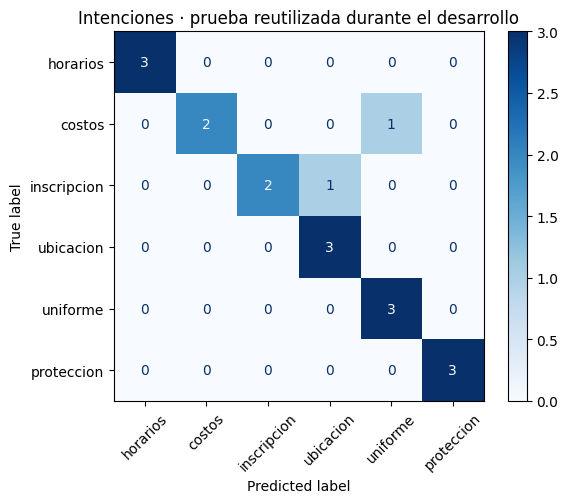

'¿Qué cuesta el uniforme?' real: costos predicha: uniforme
'¿Cómo puedo entrar a MDK?' real: inscripcion predicha: ubicacion


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

frases = [s for grupo in EJEMPLOS.values() for s in grupo]
etiquetas = [k for k, grupo in EJEMPLOS.items() for _ in grupo]
x_entrena, x_prueba, y_entrena, y_prueba = train_test_split(
    frases, etiquetas, test_size=.25, random_state=42, stratify=etiquetas)
x_entrena += [s for grupo in REFUERZO.values() for s in grupo]
y_entrena += [k for k, grupo in REFUERZO.items() for _ in grupo]
modelo_texto = Pipeline([
    ('tfidf', TfidfVectorizer(tokenizer=preprocesar, token_pattern=None,
                              lowercase=False, ngram_range=(1, 2))),
    ('svm', LinearSVC(random_state=42))
])
modelo_texto.fit(x_entrena, y_entrena)
pronostico_texto = modelo_texto.predict(x_prueba)
print('Entrenamiento:', len(x_entrena), '| Prueba:', len(x_prueba))
print('Exactitud:', round(accuracy_score(y_prueba, pronostico_texto), 3))
print(classification_report(y_prueba, pronostico_texto, labels=list(EJEMPLOS), zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_prueba, pronostico_texto, labels=list(EJEMPLOS),
                                         cmap='Blues', xticks_rotation=45)
plt.title('Intenciones · prueba reutilizada durante el desarrollo')
plt.show()
for pregunta, real, predicha in zip(x_prueba, y_prueba, pronostico_texto):
    if real != predicha: print(repr(pregunta), 'real:', real, 'predicha:', predicha)

## 5. Conjunto de imágenes

El conjunto visual contiene fotografías de cascos, guantes, petos y uniformes de taekwondo. Las imágenes se organizaron en grupos de entrenamiento, validación y prueba para desarrollar y evaluar el clasificador.

In [ ]:
import os, random, zipfile
from pathlib import Path
import numpy as np
import tensorflow as tf
from google.colab import files

SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

subidos = files.upload()
nombre_zip = 'MDK_imagenes_clasificadas.zip'
assert nombre_zip in subidos, f'Sube el archivo {nombre_zip}'
carpeta = Path('/content/mdk_imagenes')
carpeta.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(nombre_zip) as z:
    z.extractall(carpeta)
for parte in ('entrenamiento', 'validacion', 'prueba'):
    print(parte, {p.name: len(list(p.glob('*.jpg'))) for p in sorted((carpeta / parte).iterdir()) if p.is_dir()})

TensorFlow: 2.21.0
GPU: []


Saving MDK_imagenes_clasificadas.zip to MDK_imagenes_clasificadas.zip
entrenamiento {'casco': 34, 'guantes': 21, 'peto': 44, 'uniforme': 19}
validacion {'casco': 7, 'guantes': 4, 'peto': 9, 'uniforme': 4}
prueba {'casco': 7, 'guantes': 4, 'peto': 9, 'uniforme': 4}


## 6. Clasificador visual

Se utiliza EfficientNetB0 con transferencia de aprendizaje. La base preentrenada permanece congelada y se entrena una nueva capa de salida para distinguir las cuatro categorías de artículos.

In [ ]:
TAMANO = (224, 224)
LOTE = 16
clases = ['casco', 'guantes', 'peto', 'uniforme']

def cargar(parte, revolver):
    return tf.keras.utils.image_dataset_from_directory(
        carpeta / parte, labels='inferred', label_mode='int',
        class_names=clases, image_size=TAMANO, batch_size=LOTE,
        shuffle=revolver, seed=SEMILLA if revolver else None,
    ).prefetch(tf.data.AUTOTUNE)

entrenamiento = cargar('entrenamiento', True)
validacion = cargar('validacion', False)
prueba = cargar('prueba', False)
print('Orden de clases:', clases)

Found 118 files belonging to 4 classes.
Found 24 files belonging to 4 classes.
Found 24 files belonging to 4 classes.
Orden de clases: ['casco', 'guantes', 'peto', 'uniforme']


In [ ]:
aumento = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name='aumento')

base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', input_shape=(224, 224, 3)
)
base.trainable = False
entradas = tf.keras.Input(shape=(224, 224, 3))
x = aumento(entradas)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
salidas = tf.keras.layers.Dense(len(clases), activation='softmax')(x)
modelo_visual = tf.keras.Model(entradas, salidas)
modelo_visual.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)
historial = modelo_visual.fit(
    entrenamiento, validation_data=validacion, epochs=20,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True
    )],
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.4153 - loss: 1.2197 - val_accuracy: 0.8333 - val_loss: 0.7821
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.7966 - loss: 0.6803 - val_accuracy: 0.9583 - val_loss: 0.4350
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9492 - loss: 0.4345 - val_accuracy: 1.0000 - val_loss: 0.2546
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9915 - loss: 0.2647 - val_accuracy: 1.0000 - val_loss: 0.1599
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 1.0000 - loss: 0.1760 - val_accuracy: 1.0000 - val_loss: 0.1124
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.9831 - loss: 0.1465 - val_accuracy: 1.0000 - val_loss: 0.0873
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 1.0000 - loss: 0.1110 - val_accuracy: 1.0000 - val_loss: 0.0723
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9915 - loss: 0.1097

## 7. Evaluación del clasificador visual

El modelo se evalúa con imágenes reservadas para prueba. Se presentan las curvas de entrenamiento, accuracy, precisión, recall, F1-score y matriz de confusión.

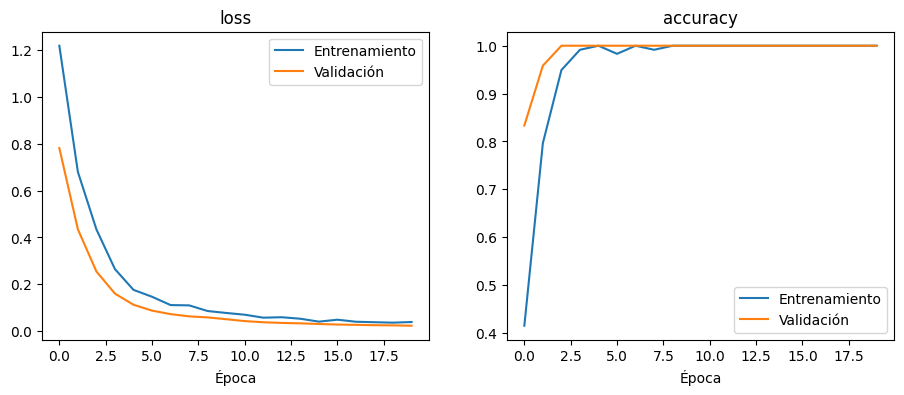

Accuracy de prueba: 1.0
              precision    recall  f1-score   support

       casco       1.00      1.00      1.00         7
     guantes       1.00      1.00      1.00         4
        peto       1.00      1.00      1.00         9
    uniforme       1.00      1.00      1.00         4

    accuracy                           1.00        24
   macro avg       1.00      1.00      1.00        24
weighted avg       1.00      1.00      1.00        24



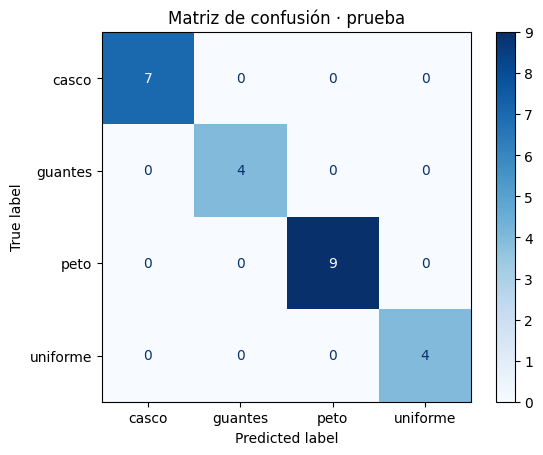

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, metrica in zip(ejes, ('loss', 'accuracy')):
    eje.plot(historial.history[metrica], label='Entrenamiento')
    eje.plot(historial.history['val_' + metrica], label='Validación')
    eje.set_title(metrica)
    eje.set_xlabel('Época')
    eje.legend()
plt.show()

reales = np.concatenate([y.numpy() for _, y in prueba])
probabilidades = modelo_visual.predict(prueba, verbose=0)
predichas = np.argmax(probabilidades, axis=1)
print('Accuracy de prueba:', round(accuracy_score(reales, predichas), 3))
print(classification_report(reales, predichas, labels=range(len(clases)), target_names=clases, zero_division=0))
matriz = confusion_matrix(reales, predichas, labels=range(len(clases)))
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión · prueba')
plt.show()

## 8. Integración de texto e imagen

La respuesta combina la pregunta con el artículo reconocido en la fotografía. El asistente informa precios y condiciones de compra establecidos por la escuela, sin inferir tallas, estado físico o aceptación de artículos externos a partir de una imagen.


In [ ]:
from PIL import Image
import numpy as np

RESPUESTAS_SEGURO = {
    'horarios': ESCUELA['horarios'],
    'ubicacion': 'Estamos en ' + ESCUELA['direccion'] + '.',
    'inscripcion': 'Podemos orientarte sobre la inscripción. ' + CONTACTO,
    'costos': 'Los costos publicados en este prototipo deben confirmarse con la escuela. ' + CONTACTO,
    'uniforme': respuesta_equipo('¿Qué incluye el uniforme?'),
    'proteccion': respuesta_equipo('¿Qué incluye el equipo de protección?'),
}

def integrar(pregunta, foto=None, bot=None):
    bot = bot if bot is not None else ChatbotMDK()
    resultado = bot.responder(pregunta)
    respuesta = resultado['respuesta']
    origen = 'reglas'
    if resultado['intenciones'] == ['desconocida'] and foto is None:
        vec = modelo_texto.named_steps['tfidf'].transform([pregunta])
        if vec.nnz:
            puntajes = modelo_texto.decision_function([pregunta])[0]
            orden = np.argsort(puntajes)[::-1]
            if puntajes[orden[0]] - puntajes[orden[1]] >= 0.25:
                etiqueta = modelo_texto.named_steps['svm'].classes_[orden[0]]
                respuesta = RESPUESTAS_SEGURO[etiqueta]
                origen = 'svm con respuesta controlada'
            else:
                origen = 'atención humana por ambigüedad'
        else:
            origen = 'atención humana por falta de vocabulario'
    visual = None
    if foto is not None:
        imagen = Image.open(foto).convert('RGB').resize((224, 224))
        arreglo = tf.keras.utils.img_to_array(imagen)[None, ...]
        scores = modelo_visual.predict(arreglo, verbose=0)[0]
        idx = int(np.argmax(scores))
        visual = {'categoria': clases[idx], 'puntuacion_softmax': float(scores[idx])}
        if scores[idx] >= 0.65:
            reconocido = 'careta' if clases[idx] == 'casco' else clases[idx]
            declarado = articulo_mencionado(normalizar(pregunta))
            if declarado and declarado != reconocido:
                respuesta = (f'La foto parece mostrar {reconocido}, no {declarado}. '
                             'La clasificación puede equivocarse; envía otra foto si deseas revisarlo. '
                             'El uniforme y el equipo oficial se adquieren en la escuela.')
            else:
                respuesta = respuesta_equipo(pregunta, reconocido, foto=True)
            origen = 'clasificación visual y consulta del usuario'
        else:
            respuesta = ('No distingo con suficiente claridad el artículo de la foto. '
                         'Envía otra imagen o consulta directamente con la escuela.')
            origen = 'imagen no concluyente'
    return {'pregunta': pregunta, 'intenciones_reglas': resultado['intenciones'],
            'origen_respuesta': origen, 'imagen': visual, 'respuesta': respuesta}

# Tres operaciones: texto, foto, resultado comunicado en una misma respuesta.
print(integrar('¿Qué días tienen clase?')['respuesta'])
print('\nEjemplo solo de texto:', integrar('Me puedes dar referencias del lugar porque no lo encuentro')['respuesta'])

¡Claro! Tenemos clases de lunes a jueves: 5:00–6:00 p. m., Preescolar e Infantil Menor (aprox. 3–9 años); 6:00–7:00 p. m., Infantil Mayor y Juveniles (aprox. 9 años en adelante). Te ayudamos a elegir el grupo según la edad y el nivel del alumno; a los 9 años valoramos cuál de los dos turnos le conviene.

Ejemplo solo de texto: Estamos en Boulevard Paso Limón #1621, colonia Paso Limón, Tuxtla Gutiérrez, Chiapas, a un costado del OXXO.


## 9. Prueba de la integración

Se presenta una consulta acompañada de una fotografía para observar cómo el sistema procesa el texto, clasifica el artículo y comunica ambos resultados en una respuesta.

In [ ]:
from google.colab import files
pregunta_usuario = '¿Qué es este artículo y necesito comprarlo para comenzar?'
fotos_usuario = files.upload()
if fotos_usuario:
    import pprint
    pprint.pp(integrar(pregunta_usuario, next(iter(fotos_usuario))))

Saving images.jpg to images.jpg
{'pregunta': '¿Qué es este artículo y necesito comprarlo para comenzar?',
 'intenciones_reglas': ['desconocida'],
 'origen_respuesta': 'clasificación visual y consulta del usuario',
 'imagen': {'categoria': 'casco', 'puntuacion_softmax': 0.8007896542549133},
 'respuesta': 'En la foto parece haber un careta (casco de protección). Para '
              'entrenar se utiliza el equipo oficial adquirido en la escuela; '
              'una foto no permite comprobar su talla ni su estado. El '
              'uniforme y todo el equipo de protección oficial se adquieren '
              'exclusivamente en la escuela.'}


## 10. Conservación del modelo visual

El modelo visual entrenado se guarda en formato Keras para permitir su uso posterior sin repetir el entrenamiento.

In [15]:
from google.colab import files
modelo_visual.save('/content/mdk_clasificador_visual.keras')
print('Modelo guardado. Descárgalo si deseas conservarlo al cerrar Colab.')
# Descomenta la siguiente línea para descargarlo:
# files.download('/content/mdk_clasificador_visual.keras')

Modelo guardado. Descárgalo si deseas conservarlo al cerrar Colab.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 11. Prueba de interacción con el usuario

El asistente permite conversar mediante preguntas escritas y adjuntar una fotografía. Cuando se incluye una imagen, el sistema identifica la categoría del artículo y responde según la consulta formulada.


In [ ]:
import html
import tempfile
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

bot_chat = ChatbotMDK()

pregunta_chat = widgets.Textarea(
    placeholder="Escribe tu pregunta...",
    layout=widgets.Layout(width="100%", height="70px")
)
foto_chat = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Adjuntar foto"
)
enviar_chat = widgets.Button(description="Enviar", button_style="success")
nuevo_chat = widgets.Button(description="Nueva conversación")
salida_chat = widgets.Output(
    layout=widgets.Layout(
        border="1px solid #cccccc",
        width="100%",
        height="350px",
        overflow="auto",
        padding="10px"
    )
)

def obtener_foto():
    """Lee el archivo adjunto en versiones recientes y anteriores de ipywidgets."""
    archivos = foto_chat.value
    if not archivos:
        return None

    archivo = (
        next(iter(archivos.values()))
        if isinstance(archivos, dict)
        else archivos[0]
    )
    contenido = archivo["content"]

    with tempfile.NamedTemporaryFile(suffix=".jpg", delete=False) as temporal:
        temporal.write(bytes(contenido))
        return temporal.name

def mostrar_mensaje(autor, mensaje):
    texto_seguro = html.escape(str(mensaje)).replace("\n", "<br>")
    with salida_chat:
        display(HTML(f"<p><b>{html.escape(autor)}:</b> {texto_seguro}</p>"))

def reiniciar_adjunto():
    global foto_chat
    foto_chat = widgets.FileUpload(
        accept="image/*", multiple=False, description="Adjuntar foto"
    )
    controles_chat.children = (foto_chat, enviar_chat, nuevo_chat)

def enviar_mensaje(_):
    pregunta = pregunta_chat.value.strip()
    if not pregunta:
        mostrar_mensaje("Asistente", "Escribe una pregunta para comenzar.")
        return

    mostrar_mensaje("Tú", pregunta)
    ruta_foto = obtener_foto()

    try:
        resultado = integrar(pregunta, foto=ruta_foto, bot=bot_chat)
        mostrar_mensaje("Asistente", resultado["respuesta"])
    except Exception as error:
        mostrar_mensaje("Sistema", f"No se pudo procesar la consulta: {error}")
    finally:
        if ruta_foto:
            Path(ruta_foto).unlink(missing_ok=True)
        pregunta_chat.value = ""
        reiniciar_adjunto()

def nueva_conversacion(_):
    global bot_chat
    bot_chat = ChatbotMDK()
    pregunta_chat.value = ""
    reiniciar_adjunto()
    with salida_chat:
        clear_output()
    mostrar_mensaje("Asistente", "¡Hola! ¿En qué podemos ayudarte?")

enviar_chat.on_click(enviar_mensaje)
nuevo_chat.on_click(nueva_conversacion)

controles_chat = widgets.HBox([foto_chat, enviar_chat, nuevo_chat])
display(widgets.VBox([
    widgets.HTML("<h3>Asistente MDK Tuchtlán</h3>"),
    salida_chat,
    pregunta_chat,
    controles_chat
]))

mostrar_mensaje("Asistente", "¡Hola! Puedes preguntar por horarios, inscripción, costos, ubicación, uniforme o equipo de protección.")

In [16]:
import shutil

shutil.copy2(
    "/content/MDK_imagenes_clasificadas.zip",
    "/content/drive/MyDrive/Chatbot_MDK_Tuchtlan/MDK_imagenes_clasificadas.zip"
)

'/content/drive/MyDrive/Chatbot_MDK_Tuchtlan/MDK_imagenes_clasificadas.zip'

## Referencias

- Scikit-learn, [TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html).
- TensorFlow Keras, [EfficientNet](https://www.tensorflow.org/api_docs/python/tf/keras/applications/EfficientNetB0) y [transferencia de aprendizaje](https://www.tensorflow.org/tutorials/images/transfer_learning).
- Proyecto 1, chatbot MDK Tuchtlán y pruebas locales, octubre de 2026.